<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    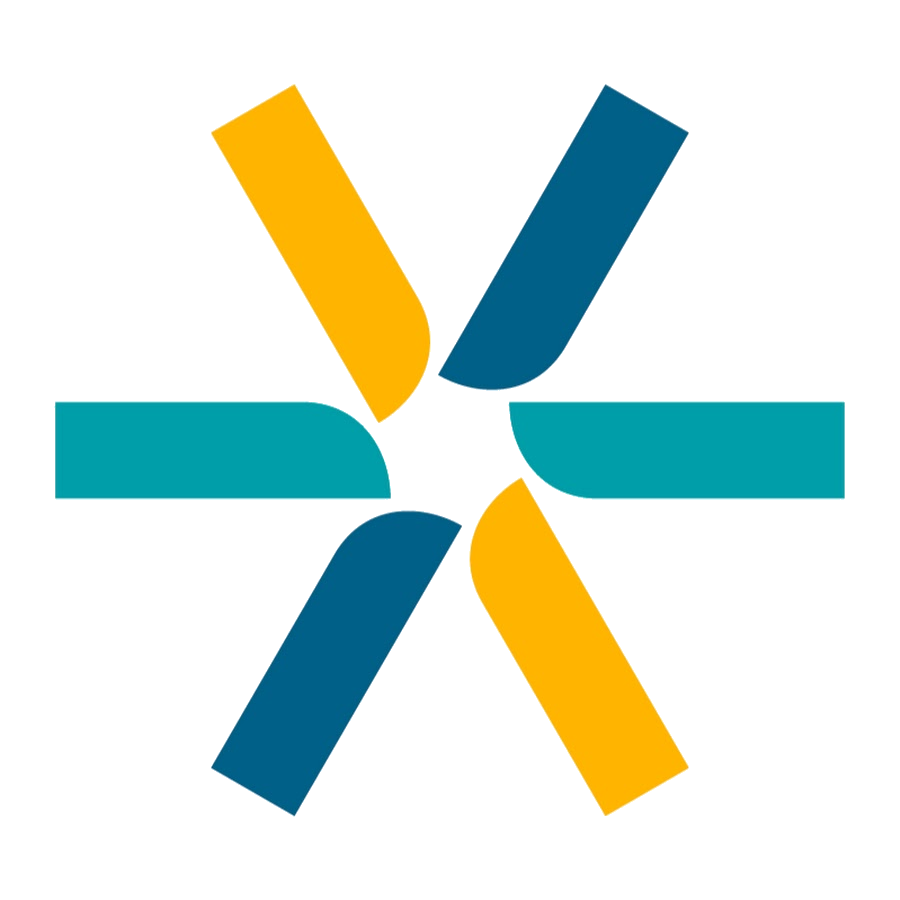
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Regresión lineal · aplicada a la demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 6 · Modelos lineales de regresión</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 29 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">¿Cuántos MWh va a demandar un agente del Mercado Eléctrico Mayorista (una distribuidora en una tarifa, o un gran usuario) en un mes dado? Un número, no una categoría: es un problema de <b>regresión</b>.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">demanda-ltimos-aos.csv</code> de CAMMESA (datos.energia.gob.ar): ~40 000 filas, cada una es la demanda mensual de un agente en una tarifa, de 2017-01 a 2020-02.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El cambio respecto de la clase</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">En el cuaderno de la cátedra las predictoras ya eran columnas numéricas. Acá casi todas son categóricas, así que las predictoras <b>se construyen</b>: la demanda del mismo agente el mes anterior, dos meses antes y doce meses antes (rezagos), el mes del año y dos indicadores 0/1. Son seis, como en la clase.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas 8 secciones de la clase 29: datos → dejarlos listos → el algoritmo → resultado contra la línea de base → variantes (ecuación normal, gradiente, SGDRegressor, minilotes) → comparativo → usarlo → qué quedó.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre un conjunto de prueba que el modelo no vio, en MWh, contra <b>dos</b> referencias: predecir la media (la de la clase) y predecir «lo mismo que el mes pasado» (la de las series de tiempo, mucho más difícil de ganar).</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Dos diferencias de fondo con el ejemplo del gimnasio</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>1 · Es una serie de tiempo.</b> En la clase se parte al azar con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">train_test_split</code>. Acá eso haría trampa: el modelo vería meses del futuro para predecir el pasado. Se parte <b>por fecha</b>: se entrena hasta 2019-06 y se prueba de 2019-07 a 2020-02. La validación cruzada también respeta el orden, con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>2 · Las predictoras están muy correlacionadas entre sí.</b> La demanda de un mes se parece muchísimo a la del mes anterior y a la de dos meses antes. En el gimnasio las predictoras eran independientes y cada coeficiente se leía por separado; acá eso cambia, y se va a ver en los coeficientes y en el descenso de gradiente.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos</h2></div>

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 120)
np.set_printoptions(suppress=True, precision=2)
import warnings
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # los primeros pliegues temporales (2017) no tienen lag12: es esperable

# Rutas relativas (nada absoluto): se busca el CSV junto al cuaderno o en una carpeta datos/
CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")

# El archivo trae BOM (utf-8-sig) y indice_tiempo tiene que quedar como texto
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
print(f"{demanda.shape[0]} filas · {demanda.shape[1]} columnas · de {demanda['indice_tiempo'].min()} a {demanda['indice_tiempo'].max()}")
demanda.head()

40388 filas · 16 columnas · de 2017-01 a 2020-02


,id,anio,mes,agente_nemo,agente_descripcion,tipo_agente,region,provincia,categoria_area,categoria_demanda,tarifa,categoria_tarifa,demanda_MWh,fecha_proceso,lote_id_log,indice_tiempo
0,699232,2017,1,AARGTAOY,AEROP ARG 2000 - Aeroparque,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,1990.439,2020-05-05 11:06:49.000713,67,2017-01
1,699233,2017,1,ABRILHCY,ABRIL CLUB DE CAMPO,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,1609.464,2020-05-05 11:06:49.000713,67,2017-01
2,699234,2017,1,ACARQQ3Y,ASOC.COOP.ARG. - Quequén,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,421.334,2020-05-05 11:06:49.000713,67,2017-01
3,699235,2017,1,ACARSLSY,ASOC.COOP.ARG. - San Lorenzo,GU,LITORAL,SANTA FE,Gran Usuario MEM,Gran Usuario,GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,449.145,2020-05-05 11:06:49.000713,67,2017-01
4,699236,2017,1,ACERBR1Y,Planta Bragado,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,18073.170,2020-05-05 11:06:49.000713,67,2017-01


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Construir las predictoras</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Una <b>serie</b> es un agente en una tarifa (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">agente_nemo</code> + <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">tarifa</code>): por ejemplo, una distribuidora en tarifa residencial. Para cada fila se busca la demanda de esa misma serie 1, 2 y 12 meses antes. Se hace con un <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">merge</code> por período y no con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">shift</code>, porque hay series a las que les faltan meses: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">shift</code> tomaría el mes equivocado sin avisar.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las seis predictoras: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> (MWh), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code> (1 a 12), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code> (0/1). El objetivo: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">demanda_MWh</code>.</p></div>

In [2]:
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]

def rezago(k):
    """La demanda de cada serie, corrida k meses hacia adelante: queda alineada con la fila k meses después."""
    t = base_lags.copy()
    t["periodo"] = t["periodo"] + k
    return t.rename(columns={"demanda_MWh": f"lag{k}"})

for k in [1, 2, 12]:
    demanda = demanda.merge(rezago(k), on=["serie", "periodo"], how="left")

demanda["mes_num"] = demanda["periodo"].dt.month
demanda["es_gran_usuario"] = (demanda["categoria_demanda"] == "Gran Usuario").astype(int)
demanda["es_residencial"] = (demanda["categoria_tarifa"] == "Residencial").astype(int)

PREDICTORAS = ["lag1", "lag2", "lag12", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "demanda_MWh"

# Sin el mes anterior no hay nada que predecir con esta lógica: esas filas salen (son el primer mes de cada serie)
datos = demanda[demanda["lag1"].notna()].sort_values(["periodo", "serie"]).reset_index(drop=True)
print(f"Filas con mes anterior disponible: {len(datos)} de {len(demanda)}  ·  series distintas: {datos['serie'].nunique()}")
print("\nFaltantes por columna (en %):")
print((datos[PREDICTORAS + [OBJETIVO]].isna().mean() * 100).round(1).to_string())
datos[PREDICTORAS + [OBJETIVO]].describe().round(1)

Filas con mes anterior disponible: 38077 de 40388  ·  series distintas: 1664

Faltantes por columna (en %):
lag1                0.0
lag2                4.7
lag12              43.5
mes_num             0.0
es_gran_usuario     0.0
es_residencial      0.0
demanda_MWh         0.0


,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial,demanda_MWh
count,38077.0,36285.0,21512.0,38077.0,38077.0,38077.0,38077.0
mean,10565.3,10660.0,11576.3,6.4,0.5,0.4,10586.7
std,46356.5,46271.7,45768.8,3.4,0.5,0.5,46618.8
min,-6554.3,-1757.1,-0.0,1.0,0.0,0.0,-6554.3
25%,319.9,344.8,547.4,3.0,0.0,0.0,317.8
50%,1277.7,1319.7,1580.9,6.0,0.0,0.0,1274.1
75%,4416.5,4501.9,5079.9,9.0,1.0,1.0,4405.1
max,1572308.1,1572308.1,1046149.6,12.0,1.0,1.0,1572308.1


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> falta en casi la mitad de las filas: todo 2017 no tiene año anterior, y en 2019 CAMMESA recategorizó tarifas (las series bajan de ~1200 a ~790 por mes), así que muchas series «nuevas» no tienen historia. Se imputa con la mediana, igual que en la clase, pero es una imputación pobre: a una distribuidora gigante le pone el valor de un agente chico. Queda anotado como límite.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El objetivo va de valores negativos (ajustes contables, menos del 1 % de estas filas) a más de un millón de MWh: es extremadamente asimétrico, mucho más que las sesiones del gimnasio.</p></div>

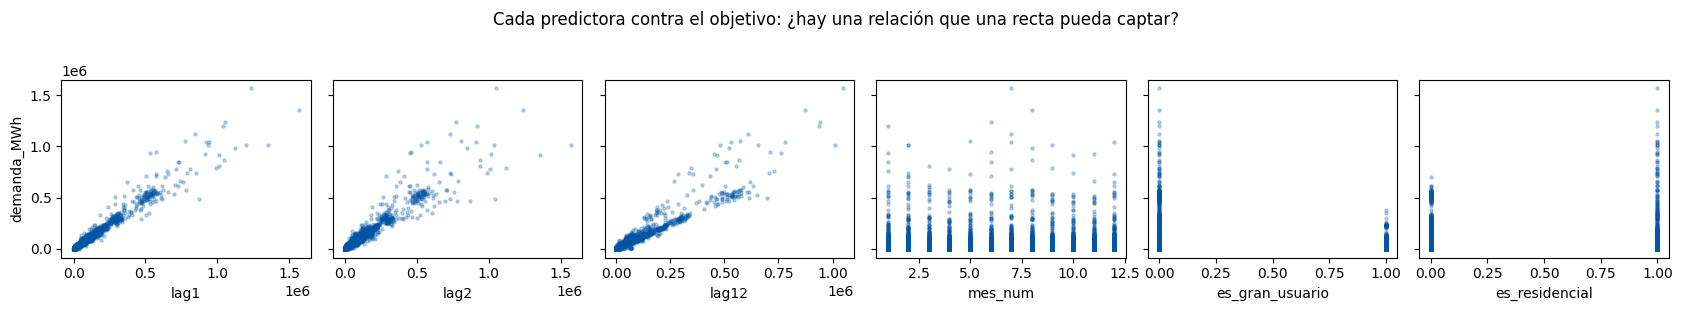

In [3]:
fig, ejes = plt.subplots(1, 6, figsize=(17, 3.0), sharey=True)
for ax, col in zip(ejes, PREDICTORAS):
    ax.scatter(datos[col], datos[OBJETIVO], s=5, alpha=0.25, color=AZUL)
    ax.set_xlabel(col)
ejes[0].set_ylabel(OBJETIVO)
fig.suptitle("Cada predictora contra el objetivo: ¿hay una relación que una recta pueda captar?", y=1.02)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los tres rezagos dibujan casi una diagonal perfecta: la demanda de un agente este mes es, ante todo, la de los meses anteriores. El mes del año y los dos indicadores 0/1 aparecen como columnas de puntos verticales sin tendencia clara. Una recta va a confirmarlo con números.</p></div>

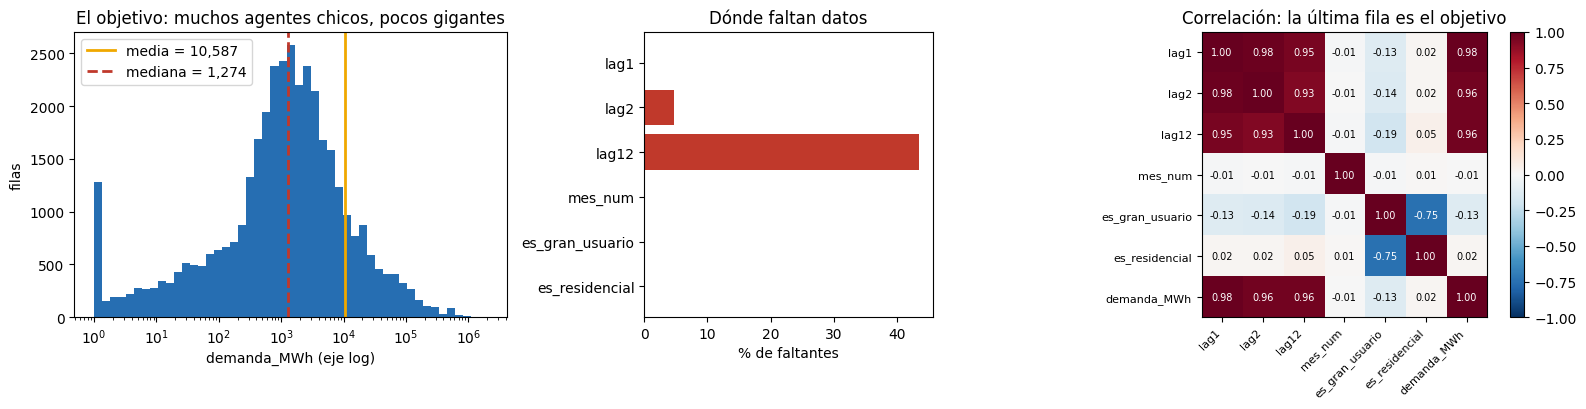

In [4]:
fig, (a, b, cmat) = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [3, 2, 3.2]})
a.hist(datos[OBJETIVO].clip(lower=1), bins=np.logspace(0, 6.3, 50), color=AZUL, alpha=0.85); a.set_xscale("log")
a.axvline(datos[OBJETIVO].mean(), color=AMBAR, lw=2, label=f"media = {datos[OBJETIVO].mean():,.0f}")
a.axvline(datos[OBJETIVO].median(), color=ROJO, lw=2, ls="--", label=f"mediana = {datos[OBJETIVO].median():,.0f}")
a.set_xlabel(OBJETIVO + " (eje log)"); a.set_ylabel("filas"); a.set_title("El objetivo: muchos agentes chicos, pocos gigantes"); a.legend()
falt = datos[PREDICTORAS].isna().mean() * 100
b.barh(falt.index, falt.values, color=[ROJO if v > 0 else GRIS for v in falt.values]); b.set_xlabel("% de faltantes"); b.set_title("Dónde faltan datos"); b.invert_yaxis()
corr = datos[PREDICTORAS + [OBJETIVO]].corr()
im = cmat.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
cmat.set_xticks(range(len(corr))); cmat.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
cmat.set_yticks(range(len(corr))); cmat.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        cmat.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
cmat.set_title("Correlación: la última fila es el objetivo"); plt.colorbar(im, ax=cmat, fraction=0.046)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La media es varias veces la mediana: unos pocos agentes enormes (las grandes distribuidoras) arrastran el promedio. En la matriz, la última fila confirma lo de las dispersiones: correlaciones de 0,96 a 0,98 con los rezagos, casi cero con el resto.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Pero mirá el bloque de arriba a la izquierda: los rezagos están correlacionados <b>entre sí</b> en 0,93–0,98. En el gimnasio pasaba lo contrario y por eso cada coeficiente se leía por separado. Acá los tres rezagos cuentan casi la misma historia, y la recta va a tener que repartir el peso entre ellos (multicolinealidad).</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">2 · Dejarlo listo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las mismas tres cosas que en la clase: partir en entrenamiento y prueba; imputar; escalar. La diferencia es que el corte es <b>temporal</b>. Y antes de cualquier modelo, las líneas de base.</p></div>

In [5]:
CORTE = pd.Period("2019-06", freq="M")                  # se entrena hasta acá, se prueba con lo que viene después
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
print(f"entrenamiento: {len(X_ent)} filas ({datos.loc[ent_mask, 'periodo'].min()} a {CORTE})")
print(f"prueba:        {len(X_pru)} filas ({datos.loc[~ent_mask, 'periodo'].min()} a {datos['periodo'].max()})")

entrenamiento: 31962 filas (2017-02 a 2019-06)
prueba:        6115 filas (2019-07 a 2020-02)


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo: el mismo flujo para todas las variantes."""
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), modelo)

preparar = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler())
CV = TimeSeriesSplit(n_splits=5)                       # validación cruzada que respeta el orden temporal (los datos ya están ordenados por período)
preparar

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('simpleimputer', ...), ('standardscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite impu

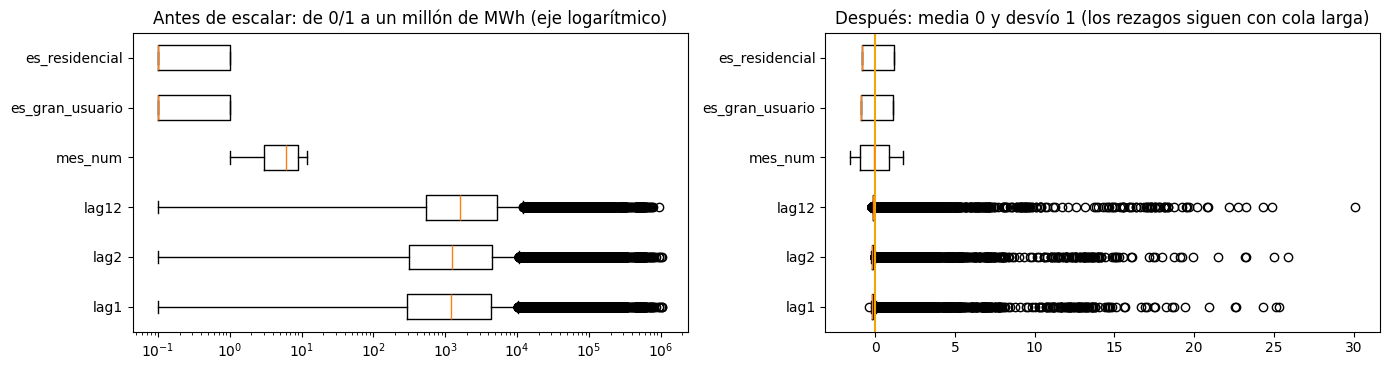

In [7]:
X_ent_esc = preparar.fit_transform(X_ent)
X_pru_esc = preparar.transform(X_pru)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8))
a.boxplot([X_ent[col].dropna().clip(lower=0.1) for col in PREDICTORAS], tick_labels=PREDICTORAS, vert=False); a.set_xscale("log")
a.set_title("Antes de escalar: de 0/1 a un millón de MWh (eje logarítmico)")
b.boxplot([X_ent_esc[:, i] for i in range(len(PREDICTORAS))], tick_labels=PREDICTORAS, vert=False)
b.axvline(0, color=AMBAR, lw=1.5); b.set_title("Después: media 0 y desvío 1 (los rezagos siguen con cola larga)")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Seis órdenes de magnitud entre columnas: sin escalar, el gradiente no tendría ninguna chance. Después de escalar quedan comparables, aunque los rezagos conservan valores de 20 o 30 desvíos: son las distribuidoras grandes. El escalado no cambia la forma de la distribución, solo la unidad.</p></div>

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rmse(y_real, y_pred):
    return np.sqrt(mean_squared_error(y_real, y_pred))

resultados = {}
def registrar(nombre, modelo):
    t0 = time.perf_counter(); modelo.fit(X_ent, y_ent); t = (time.perf_counter() - t0) * 1000
    pred = modelo.predict(X_pru)
    resultados[nombre] = {"RMSE": rmse(y_pru, pred), "MAE": mean_absolute_error(y_pru, pred),
                          "R²": r2_score(y_pru, pred), "ajuste (ms)": t, "modelo": modelo}
    return modelo

base = registrar("línea de base (media)", DummyRegressor(strategy="mean"))

# Segunda línea de base, propia de series de tiempo: "este mes = el mes pasado". No aprende nada, solo copia lag1.
pred_persist = X_pru["lag1"]
resultados["línea de base (mes anterior)"] = {"RMSE": rmse(y_pru, pred_persist), "MAE": mean_absolute_error(y_pru, pred_persist),
                                              "R²": r2_score(y_pru, pred_persist), "ajuste (ms)": 0.0, "modelo": None}
print(f"Media:        RMSE = {resultados['línea de base (media)']['RMSE']:,.0f} MWh")
print(f"Mes anterior: RMSE = {resultados['línea de base (mes anterior)']['RMSE']:,.0f} MWh   ← la que de verdad hay que ganarle")

Media:        RMSE = 66,699 MWh
Mes anterior: RMSE = 10,463 MWh   ← la que de verdad hay que ganarle


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Dos referencias, no una</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ganarle a la media es fácil cuando se tiene el mes anterior: cualquier cosa que use <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> lo logra. La pregunta honesta es si la recta agrega algo sobre copiar el mes pasado. Esa es la vara.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">3 · El algoritmo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La sentencia</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Exactamente la misma que en la clase: se crea el modelo, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit</code> aprende <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">intercept_</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">coef_</code>, y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> hace una suma ponderada por fila, adentro del flujo.</p></div>

In [9]:
from sklearn.linear_model import LinearRegression

modelo = preparado(LinearRegression())
modelo.fit(X_ent, y_ent)
modelo.predict(X_pru.head())

array([ 1302.45,  1269.  ,   276.76,   384.05, 20814.95])

intercept_ = 9,851 MWh  (la predicción para una fila 'promedio': todas las columnas escaladas en cero)


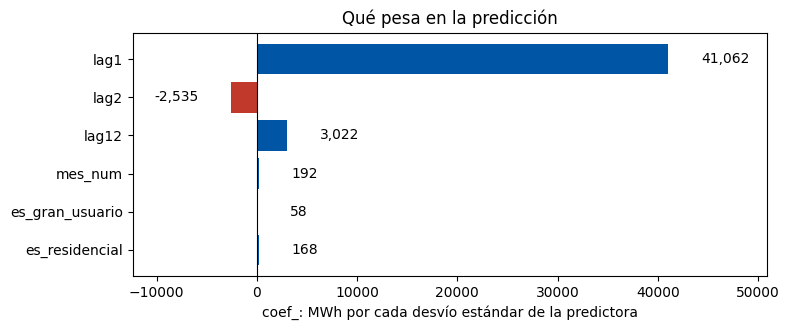

In [10]:
registrar("LinearRegression", modelo)
recta = modelo[-1]
print(f"intercept_ = {recta.intercept_:,.0f} MWh  (la predicción para una fila 'promedio': todas las columnas escaladas en cero)")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(PREDICTORAS, recta.coef_, color=[AZUL if v >= 0 else ROJO for v in recta.coef_])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("coef_: MWh por cada desvío estándar de la predictora")
margen = 0.08 * np.abs(recta.coef_).max()
ax.set_xlim(recta.coef_.min() - margen * 3, recta.coef_.max() + margen * 3)
ax.set_title("Qué pesa en la predicción"); ax.invert_yaxis()
for i, v in enumerate(recta.coef_): ax.text(v + (margen if v >= 0 else -margen), i, f"{v:,.0f}", va="center", ha="left" if v >= 0 else "right")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se lee</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada coeficiente dice cuántos MWh cambia la predicción cuando esa variable sube un desvío estándar, con las demás quietas. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> se lleva casi todo el peso; <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> aporta algo (la estacionalidad: verano e invierno); el mes y los indicadores, casi nada comparado.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ojo con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code>: puede salir negativo. No significa que «más demanda hace dos meses baje la de hoy». Como <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code> están correlacionados en 0,98, la recta reparte el peso entre los dos y el signo de uno solo deja de tener lectura propia. Es la cara práctica de la multicolinealidad: «con las demás quietas» no tiene sentido si las demás nunca se quedan quietas.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La recta que se puede ver</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con una predictora es una recta, con dos un plano. Se usan las dos que mejor cuentan la historia: el mes anterior y el mismo mes del año pasado.</p></div>

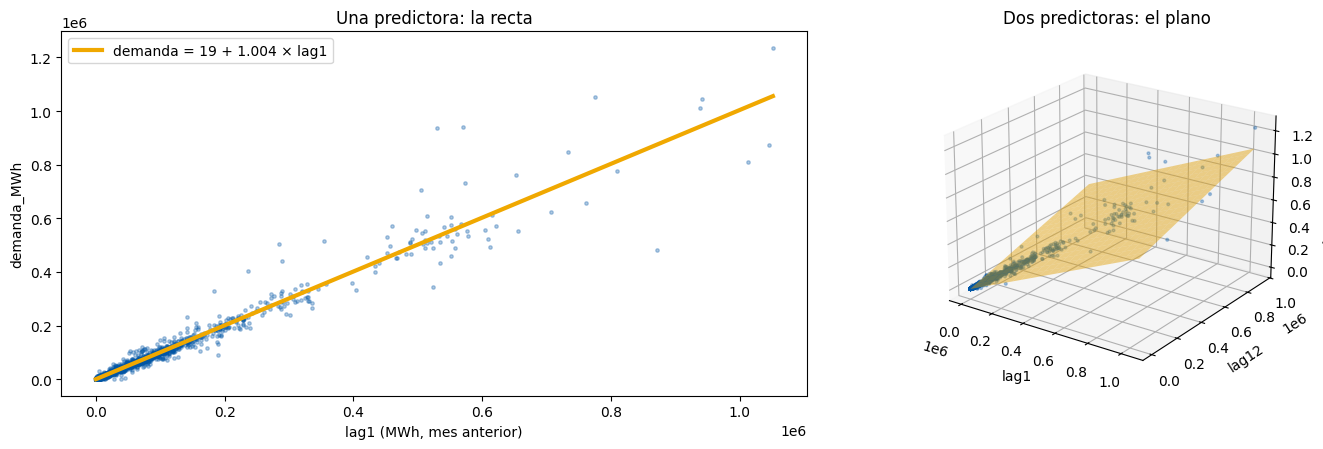

Recta (lag1): R² = 0.9655   |   Plano (lag1, lag12): R² = 0.9743   |   Hiperplano con seis (todo el entrenamiento): R² = 0.9682


In [11]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

ent = datos.loc[ent_mask].dropna(subset=["lag12"])
simple = LinearRegression().fit(ent[["lag1"]], ent[OBJETIVO])
fig = plt.figure(figsize=(15, 4.6))
a = fig.add_subplot(1, 2, 1)
a.scatter(ent["lag1"], ent[OBJETIVO], s=6, alpha=0.3, color=AZUL)
xs = np.linspace(0, ent["lag1"].max(), 50)
a.plot(xs, simple.predict(pd.DataFrame({"lag1": xs})), color=AMBAR, lw=3, label=f"demanda = {simple.intercept_:,.0f} + {simple.coef_[0]:.3f} × lag1")
a.set_xlabel("lag1 (MWh, mes anterior)"); a.set_ylabel(OBJETIVO); a.set_title("Una predictora: la recta"); a.legend()
b = fig.add_subplot(1, 2, 2, projection="3d")
plano = LinearRegression().fit(ent[["lag1", "lag12"]], ent[OBJETIVO])
b.scatter(ent["lag1"], ent["lag12"], ent[OBJETIVO], s=4, alpha=0.3, color=AZUL)
g1, g2 = np.meshgrid(np.linspace(0, ent["lag1"].max(), 20), np.linspace(0, ent["lag12"].max(), 20))
b.plot_surface(g1, g2, plano.intercept_ + plano.coef_[0] * g1 + plano.coef_[1] * g2, alpha=0.45, color=AMBAR)
b.set_xlabel("lag1"); b.set_ylabel("lag12"); b.set_zlabel(OBJETIVO); b.set_title("Dos predictoras: el plano"); b.view_init(elev=22, azim=-55)
plt.tight_layout(); plt.show()
print(f"Recta (lag1): R² = {simple.score(ent[['lag1']], ent[OBJETIVO]):.4f}   |   Plano (lag1, lag12): R² = {plano.score(ent[['lag1', 'lag12']], ent[OBJETIVO]):.4f}   |   Hiperplano con seis (todo el entrenamiento): R² = {modelo.score(X_ent, y_ent):.4f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La pendiente de la recta simple es casi 1 y la ordenada casi 0: la recta aprendió, sola, «este mes ≈ el mes pasado». El R² ya es altísimo con una sola columna, y sumar el resto mueve el tercer o cuarto decimal. En el gimnasio pasaba algo parecido con la antigüedad, pero acá es todavía más extremo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Una predicción, desarmada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> es el sesgo más la suma de coeficiente × valor escalado. Para una fila de prueba se ve cuánto aporta cada columna.</p></div>

EMISSAND | RESIDENCIAL · 2019-07: real = 105,706 MWh · predicho = 85,043 MWh


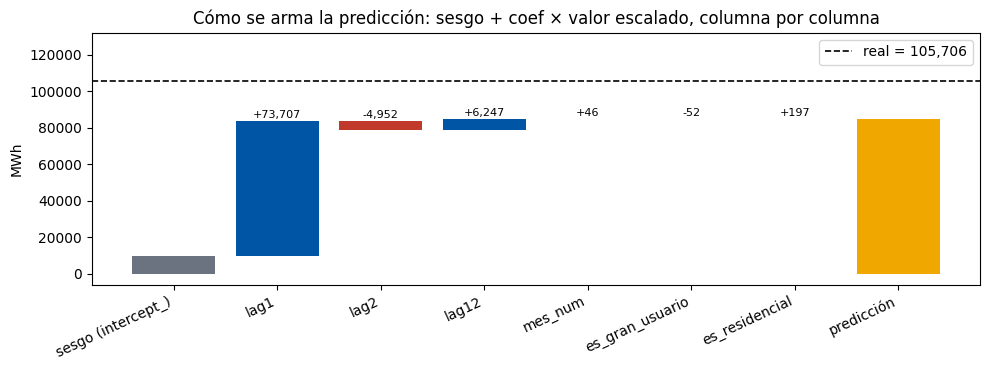

In [12]:
i = int(np.argsort(y_pru.to_numpy())[int(len(y_pru) * 0.97)])     # una fila de prueba de un agente grande (percentil 97)
z = X_pru_esc[i]
aportes = pd.Series(recta.coef_ * z, index=PREDICTORAS)
prediccion = recta.intercept_ + aportes.sum()
fila_i = datos.loc[~ent_mask].iloc[i]
print(f"{fila_i['serie']} · {fila_i['periodo']}: real = {y_pru.iloc[i]:,.0f} MWh · predicho = {prediccion:,.0f} MWh")

fig, ax = plt.subplots(figsize=(10, 3.8))
etiquetas = ["sesgo (intercept_)"] + PREDICTORAS + ["predicción"]
acum = recta.intercept_
ax.bar(0, recta.intercept_, color=GRIS)
for k, v in enumerate(aportes, start=1):
    ax.bar(k, v, bottom=acum, color=AZUL if v >= 0 else ROJO); ax.text(k, acum + max(v, 0) + abs(prediccion) * 0.02, f"{v:+,.0f}", ha="center", fontsize=8); acum += v
ax.bar(len(etiquetas) - 1, prediccion, color=AMBAR); ax.set_ylim(min(0, aportes.min() * 1.2), max(prediccion, y_pru.iloc[i]) * 1.25)
ax.axhline(y_pru.iloc[i], color="black", ls="--", lw=1.2, label=f"real = {y_pru.iloc[i]:,.0f}")
ax.set_xticks(range(len(etiquetas))); ax.set_xticklabels(etiquetas, rotation=25, ha="right"); ax.set_ylabel("MWh"); ax.legend()
ax.set_title("Cómo se arma la predicción: sesgo + coef × valor escalado, columna por columna")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se parte del sesgo (una fila promedio) y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> hace casi todo el trabajo de llevar la predicción hasta el nivel de este agente. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> corrigen hacia arriba o hacia abajo según cómo venía la serie. El resto apenas mueve la aguja.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">4 · El resultado, contra las líneas de base</h2></div>

In [13]:
y_pred = modelo.predict(X_pru)
pd.DataFrame({k: {m: v[m] for m in ["RMSE", "MAE", "R²"]} for k, v in resultados.items()}).round(3)

,línea de base (media),línea de base (mes anterior),LinearRegression
RMSE,66698.567,10463.163,9825.237
MAE,17948.702,1544.941,1605.180
R²,-0.005,0.975,0.978


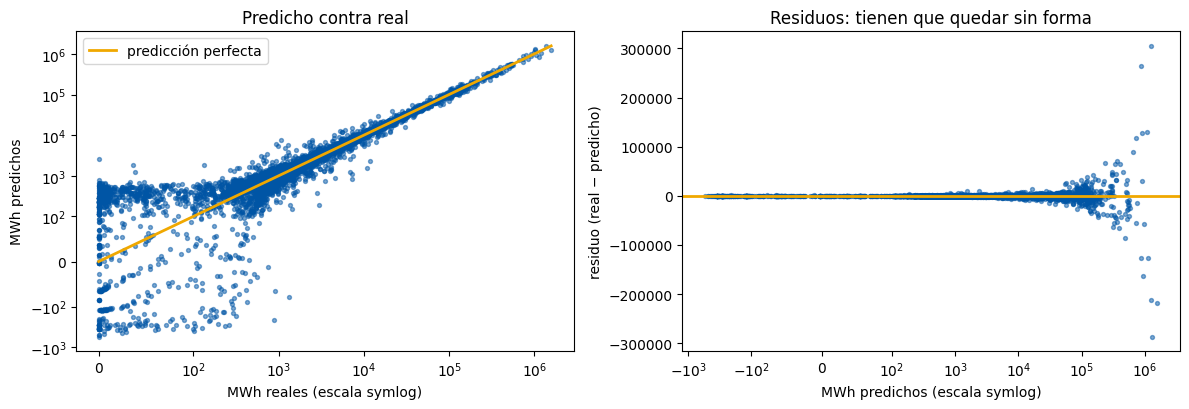

In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
a.scatter(y_pru, y_pred, s=8, alpha=0.5, color=AZUL); a.set_xscale("symlog", linthresh=100); a.set_yscale("symlog", linthresh=100)
lim = [y_pru.min(), y_pru.max()]
a.plot(lim, lim, color=AMBAR, lw=2, label="predicción perfecta")
a.set_xlabel("MWh reales (escala symlog)"); a.set_ylabel("MWh predichos"); a.set_title("Predicho contra real"); a.legend()
residuos = y_pru - y_pred
b.scatter(y_pred, residuos, s=8, alpha=0.5, color=AZUL); b.set_xscale("symlog", linthresh=100)
b.axhline(0, color=AMBAR, lw=2)
b.set_xlabel("MWh predichos (escala symlog)"); b.set_ylabel("residuo (real − predicho)"); b.set_title("Residuos: tienen que quedar sin forma")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué mirar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El R² es altísimo, pero eso se lo da casi entero <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>: mirá la fila «mes anterior» de la tabla. La comparación que importa es la recta contra copiar el mes pasado, y ahí la mejora es chica: en RMSE la recta gana por unos cientos de MWh, pero en MAE puede perder. Es decir, mejora en los agentes gigantes (que dominan el RMSE) y empeora un poco en la fila típica. Es un resultado honesto: la demanda eléctrica de un agente es muy persistente y una recta sobre estos rezagos solo la refina un poco.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">A la derecha, los residuos forman un embudo: casi cero para los agentes chicos y de miles de MWh para los grandes. El error no es parejo en toda la escala (heterocedasticidad). El RMSE lo dominan unas pocas distribuidoras grandes. Una salida habitual es modelar el logaritmo de la demanda, que queda planteado como mejora.</p></div>

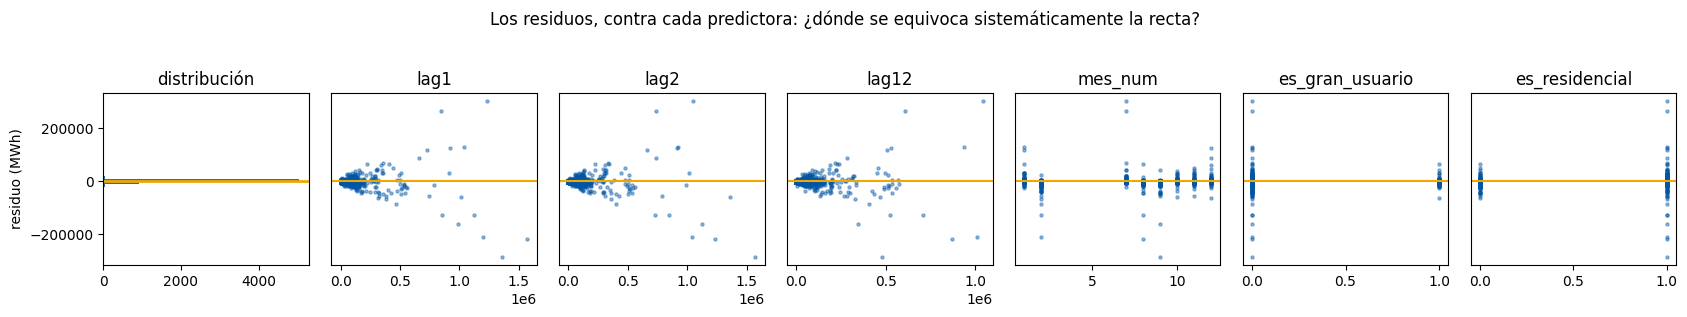

residuo medio = -216 MWh · desvío = 9,824 · el 95 % cae entre -5,965 y 4,704 MWh
error absoluto mediano = 287 MWh   ← la fila típica se predice muy bien; el RMSE lo inflan los gigantes


In [15]:
fig, ejes = plt.subplots(1, 7, figsize=(17, 3.0))
ejes[0].hist(residuos, bins=60, color=AZUL, alpha=0.85, orientation="horizontal"); ejes[0].axhline(0, color=AMBAR, lw=2)
ejes[0].set_title("distribución"); ejes[0].set_ylabel("residuo (MWh)")
for ax, col in zip(ejes[1:], PREDICTORAS):
    ax.scatter(X_pru[col], residuos, s=5, alpha=0.4, color=AZUL); ax.axhline(0, color=AMBAR, lw=1.5); ax.set_title(col); ax.set_yticks([])
fig.suptitle("Los residuos, contra cada predictora: ¿dónde se equivoca sistemáticamente la recta?", y=1.04)
plt.tight_layout(); plt.show()
print(f"residuo medio = {residuos.mean():,.0f} MWh · desvío = {residuos.std():,.0f} · el 95 % cae entre {np.percentile(residuos, 2.5):,.0f} y {np.percentile(residuos, 97.5):,.0f} MWh")
print(f"error absoluto mediano = {residuos.abs().median():,.0f} MWh   ← la fila típica se predice muy bien; el RMSE lo inflan los gigantes")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El histograma es una aguja en cero con colas largas: la mayoría de las filas tienen error chico y unas pocas, enorme. Contra los rezagos, el residuo se abre a medida que el agente es más grande. Contra el mes del año aparece cierta forma: la recta trata el mes como un número de 1 a 12, como si diciembre fuera «doce veces enero», y no puede captar que enero y diciembre (verano) se parecen. Codificarlo con indicadores por mes, o con seno y coseno, es otra mejora posible.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">¿Y con más datos mejoraría?</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La curva de aprendizaje, ahora con pliegues temporales.</p></div>

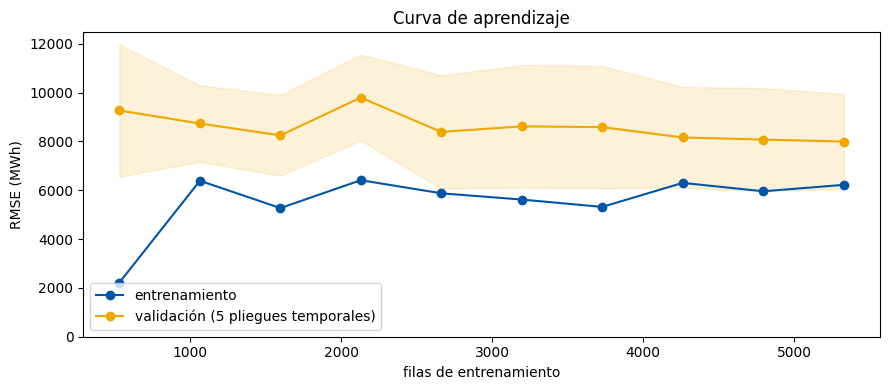

In [16]:
from sklearn.model_selection import learning_curve

tamanos, err_ent, err_val = learning_curve(preparado(LinearRegression()), X_ent, y_ent, cv=CV, train_sizes=np.linspace(0.1, 1.0, 10),
                                           scoring="neg_root_mean_squared_error")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tamanos, -err_ent.mean(axis=1), marker="o", color=AZUL, label="entrenamiento")
ax.plot(tamanos, -err_val.mean(axis=1), marker="o", color=AMBAR, label="validación (5 pliegues temporales)")
ax.fill_between(tamanos, -err_val.mean(axis=1) - err_val.std(axis=1), -err_val.mean(axis=1) + err_val.std(axis=1), color=AMBAR, alpha=0.15)
ax.set_ylim(0, None); ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("RMSE (MWh)"); ax.legend(); ax.set_title("Curva de aprendizaje")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con unos pocos miles de filas la recta ya llegó a su nivel: más datos no la mueven. La banda de validación es ancha porque cada pliegue temporal valida sobre meses distintos y algunos traen saltos de agentes grandes. Igual que en la clase: el piso lo pone la forma del modelo y la información de las columnas, no la cantidad de filas.</p></div>

In [17]:
# La prueba de honestidad: el mismo modelo SIN la historia del agente (sin rezagos). ¿Cuánto se predice solo con mes y tipo de agente?
SIN_HISTORIA = ["mes_num", "es_gran_usuario", "es_residencial"]
real = preparado(LinearRegression()).fit(X_ent[SIN_HISTORIA], y_ent)
pred_real = real.predict(X_pru[SIN_HISTORIA])
print(f"sin rezagos → RMSE = {rmse(y_pru, pred_real):,.0f} MWh  contra  media = {resultados['línea de base (media)']['RMSE']:,.0f}   |   R² = {r2_score(y_pru, pred_real):.3f}")

sin rezagos → RMSE = 66,031 MWh  contra  media = 66,699   |   R² = 0.015


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sin los rezagos, la recta prácticamente no le gana a la media. Saber el mes y si el agente es un gran usuario o una tarifa residencial no dice casi nada de <b>cuánto</b> demanda: hay distribuidoras chicas y gigantes en cada categoría. Toda la capacidad predictiva viene de la historia de cada serie. Igual que con las sesiones por mes en la clase, un R² bajo con un modelo bien ajustado es una respuesta, no un fracaso.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">5 · Las variantes</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.1 · Misma recta, otras formas de pedirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">score</code> devuelve R²; <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">cross_val_score</code> (acá con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>) da la estimación con su dispersión; <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">fit_intercept=False</code> fuerza la recta a pasar por el origen.</p></div>

In [18]:
from sklearn.model_selection import cross_val_score

print(f"score(X_pru, y_pru)  → R² = {modelo.score(X_pru, y_pru):.4f}")
rmse_cv = -cross_val_score(modelo, X_ent, y_ent, cv=CV, scoring="neg_root_mean_squared_error")
print(f"cross_val_score, 5 pliegues temporales → RMSE = {rmse_cv.mean():,.0f} ± {rmse_cv.std():,.0f} MWh")

registrar("LinearRegression sin sesgo", preparado(LinearRegression(fit_intercept=False)))
print(f"fit_intercept=False → RMSE = {resultados['LinearRegression sin sesgo']['RMSE']:,.0f} MWh")

score(X_pru, y_pru)  → R² = 0.9782
cross_val_score, 5 pliegues temporales → RMSE = 7,782 ± 1,609 MWh
fit_intercept=False → RMSE = 13,759 MWh


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con las columnas escaladas, «pasar por el origen» significa que una fila promedio predice 0 MWh: le resta a todas las predicciones el sesgo, que es la demanda media. Por eso empeora, igual que en el gimnasio.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.2 · La ecuación normal, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">θ = (XᵀX)⁻¹Xᵀy con la pseudoinversa, sobre los mismos datos escalados.</p></div>

In [19]:
X_ent_esc = preparar.fit_transform(X_ent)
X_pru_esc = preparar.transform(X_pru)
y_np = y_ent.to_numpy()
X_b = np.c_[np.ones(len(X_ent_esc)), X_ent_esc]
theta = np.linalg.pinv(X_b) @ y_np

pd.DataFrame({"ecuación normal": theta, "LinearRegression": np.r_[recta.intercept_, recta.coef_]},
             index=["sesgo"] + PREDICTORAS).round(2)

,ecuación normal,LinearRegression
sesgo,9850.54,9850.54
lag1,41062.49,41062.49
lag2,-2535.04,-2535.04
lag12,3022.27,3022.27
mes_num,191.85,191.85
es_gran_usuario,58.18,58.18
es_residencial,168.05,168.05


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.3 · Descenso de gradiente, desde cero</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El mismo bucle de la clase. Lo que cambia son las tasas que sirven: con predictoras tan correlacionadas el límite antes de divergir es más bajo. Se calcula: es 2 dividido el autovalor más grande de la matriz (2/m)·XᵀX.</p></div>

Tasa límite para estos datos: η < 0.369  (en el gimnasio el margen era mucho mayor)


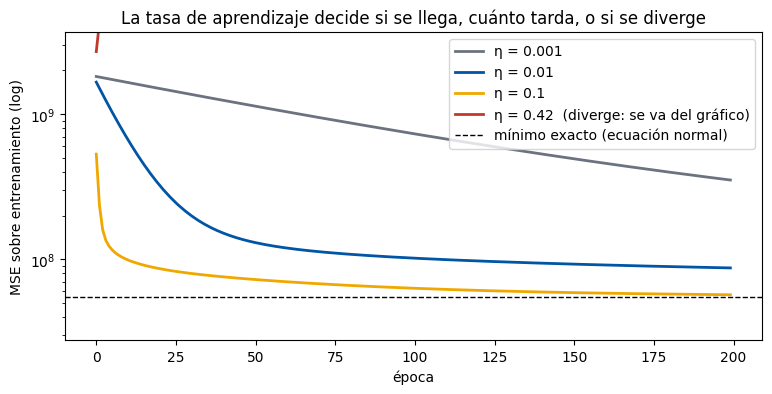

θ por gradiente (η = 0,1, 3000 épocas): [ 9851. 41062. -2535.  3022.   192.    58.   168.]
θ por ecuación normal:                   [ 9851. 41062. -2535.  3022.   192.    58.   168.]


In [20]:
def descenso(X_b, y, eta, epocas=200):
    m = len(y); theta = np.zeros(X_b.shape[1]); historia = []
    for _ in range(epocas):
        grad = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * grad
        historia.append(np.mean((X_b @ theta - y) ** 2))
    return theta, np.array(historia)

lam_max = np.linalg.eigvalsh(2 / len(X_b) * X_b.T @ X_b).max()
print(f"Tasa límite para estos datos: η < {2 / lam_max:.3f}  (en el gimnasio el margen era mucho mayor)")

mse_min = np.mean((X_b @ theta - y_np) ** 2)
mse_0 = np.mean(y_np ** 2)                                   # el MSE con θ = 0, el punto de partida
fig, ax = plt.subplots(figsize=(9, 4))
for eta, color in [(0.001, GRIS), (0.01, AZUL), (0.1, AMBAR), (round(2 / lam_max + 0.05, 2), ROJO)]:
    _, h = descenso(X_b, y_np, eta)
    ax.plot(h, color=color, lw=2, label=f"η = {eta}" + ("  (diverge: se va del gráfico)" if eta > 2 / lam_max else ""))
ax.axhline(mse_min, color="black", ls="--", lw=1, label="mínimo exacto (ecuación normal)")
ax.set_yscale("log"); ax.set_ylim(mse_min * 0.5, mse_0 * 2); ax.set_xlabel("época"); ax.set_ylabel("MSE sobre entrenamiento (log)"); ax.legend()
ax.set_title("La tasa de aprendizaje decide si se llega, cuánto tarda, o si se diverge")
plt.show()
theta_gd, _ = descenso(X_b, y_np, 0.1, epocas=3000)
print("θ por gradiente (η = 0,1, 3000 épocas):", theta_gd.round(0))
print("θ por ecuación normal:                  ", theta.round(0))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El MSE está en escala logarítmica porque se mide en MWh² y arranca altísimo. Con η = 0,1 baja rápido al principio, pero después le cuesta repartir el peso exacto entre <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code>: con muchas épocas se acerca a la ecuación normal, pero esos tres coeficientes son los últimos en acomodarse. Es el efecto de la correlación, que se ve mejor desde arriba.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">El camino del gradiente, visto desde arriba</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Curvas de nivel del costo con dos coeficientes, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> (correlacionados en 0,95), con el sesgo fijo en la media.</p></div>

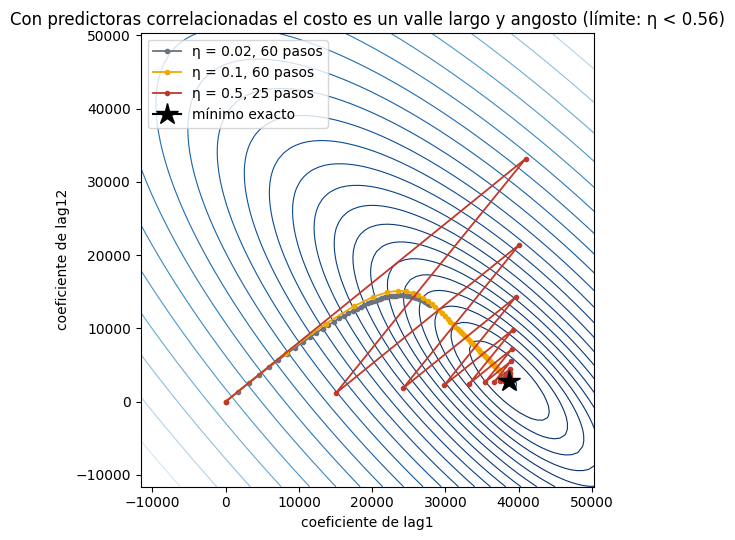

In [21]:
j1, j2 = PREDICTORAS.index("lag1"), PREDICTORAS.index("lag12")
X2 = X_ent_esc[:, [j1, j2]]; yc = y_np - y_np.mean()
t_opt = np.linalg.lstsq(X2, yc, rcond=None)[0]
def mse2(t1, t2): return np.mean((X2 @ np.array([t1, t2]) - yc) ** 2)
r1 = np.linspace(-0.3 * abs(t_opt).max(), 1.3 * abs(t_opt).max(), 80)
g1, g2 = np.meshgrid(r1, r1)
Z = np.vectorize(mse2)(g1, g2)
lam2 = np.linalg.eigvalsh(2 / len(X2) * X2.T @ X2).max()
fig, ax = plt.subplots(figsize=(9, 5.5))
cs = ax.contour(g1, g2, Z, levels=np.geomspace(Z.min() * 1.01, Z.max(), 25), cmap="Blues_r", linewidths=0.8)
for eta, color, epocas in [(0.02, GRIS, 60), (0.1, AMBAR, 60), (round(0.9 * 2 / lam2, 2), ROJO, 25)]:
    t = np.zeros(2); camino = [t.copy()]
    for _ in range(epocas):
        t = t - eta * 2 / len(yc) * X2.T @ (X2 @ t - yc); camino.append(t.copy())
    camino = np.array(camino)
    ax.plot(camino[:, 0], camino[:, 1], marker="o", ms=3, lw=1.3, color=color, label=f"η = {eta}, {epocas} pasos")
ax.plot(*t_opt, marker="*", ms=16, color="black", label="mínimo exacto")
ax.set_xlabel("coeficiente de lag1"); ax.set_ylabel("coeficiente de lag12"); ax.legend(loc="upper left"); ax.set_aspect("equal")
ax.set_title(f"Con predictoras correlacionadas el costo es un valle largo y angosto (límite: η < {2 / lam2:.2f})")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá está la gran diferencia con la clase. En el gimnasio las curvas de nivel eran casi círculos y el gradiente iba derecho al mínimo. Acá son elipses muy alargadas en diagonal: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> se pueden intercambiar (subir uno y bajar el otro) casi sin cambiar el error. El gradiente baja rápido hasta el fondo del valle y después camina despacio a lo largo de él. Con tasa grande, además, rebota de pared a pared. Escalar no alcanza para arreglarlo: la causa es la correlación, no la unidad.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.4 · SGDRegressor y sus perillas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Igual que en la clase: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">eta0</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">learning_rate</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">max_iter</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">tol</code>.</p></div>

In [22]:
from sklearn.linear_model import SGDRegressor

sgd_variantes = {
    "SGD por defecto (eta0=0.01, invscaling)": SGDRegressor(max_iter=1000, tol=1e-3, random_state=2026),
    "SGD eta0=0.001, adaptive":                SGDRegressor(max_iter=1000, tol=1e-3, eta0=0.001, learning_rate="adaptive", random_state=2026),
    "SGD eta0=0.0001, max_iter=2 (cortado)":   SGDRegressor(max_iter=2, tol=None, eta0=0.0001, random_state=2026),
}
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre, sgd in sgd_variantes.items():
        registrar(nombre, preparado(sgd))

comparacion = pd.DataFrame({"LinearRegression": recta.coef_, **{k: resultados[k]["modelo"][-1].coef_ for k in sgd_variantes}}, index=PREDICTORAS)
comparacion.round(0)

,LinearRegression,"SGD por defecto (eta0=0.01, invscaling)","SGD eta0=0.001, adaptive","SGD eta0=0.0001, max_iter=2 (cortado)"
lag1,41062.0,40613.0,40939.0,12072.0
lag2,-2535.0,-2797.0,-2458.0,11329.0
lag12,3022.0,1866.0,3057.0,8756.0
mes_num,192.0,432.0,192.0,-104.0
es_gran_usuario,58.0,233.0,67.0,-1165.0
es_residencial,168.0,281.0,177.0,-208.0


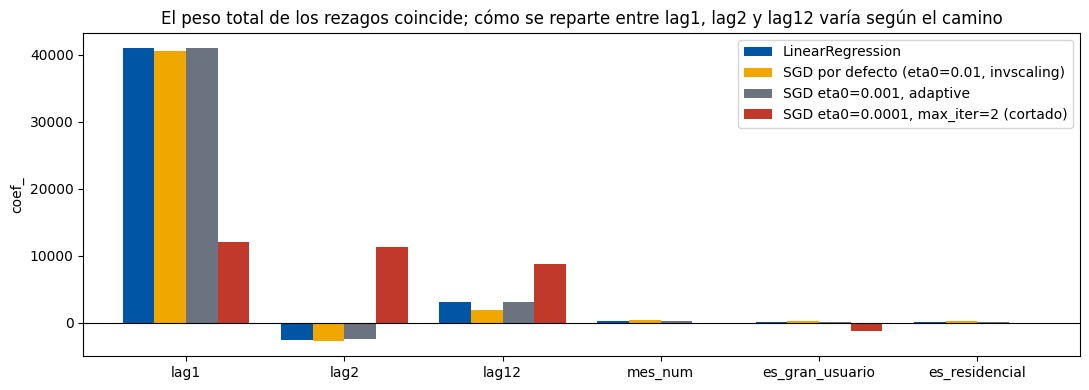

In [23]:
ax = comparacion.plot.bar(figsize=(11, 4), color=[AZUL, AMBAR, GRIS, ROJO], width=0.8)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("coef_")
ax.set_title("El peso total de los rezagos coincide; cómo se reparte entre lag1, lag2 y lag12 varía según el camino")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">¿Y los coeficientes son estables?</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se ajusta la misma recta en cinco pliegues temporales y se mira cuánto se mueve cada coeficiente. Con predictoras correlacionadas, la respuesta es la que se adelantó en la sección 3.</p></div>

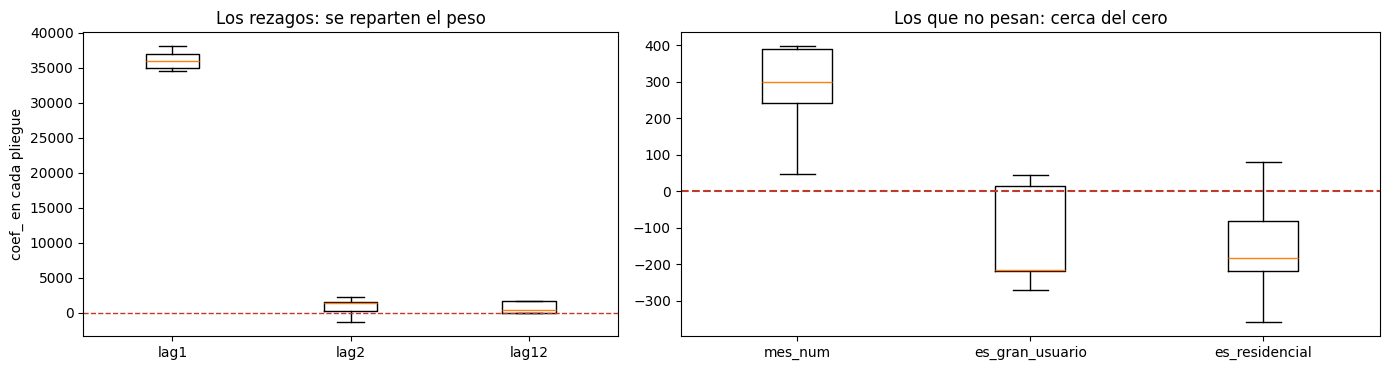

Suma lag1 + lag2 + lag12 en cada pliegue: [36842.0, 36444.0, 37810.0, 38831.0, 38357.0]


,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial
mean,36109.0,827.0,721.0,275.0,-130.0,-153.0
std,1453.0,1428.0,853.0,143.0,147.0,163.0


In [24]:
coefs_pliegues = []
for ent_idx, _ in CV.split(X_ent):
    m = preparado(LinearRegression()).fit(X_ent.iloc[ent_idx], y_ent.iloc[ent_idx])
    coefs_pliegues.append(m[-1].coef_)
coefs_pliegues = pd.DataFrame(coefs_pliegues, columns=PREDICTORAS)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1.7]})
a.boxplot([coefs_pliegues[c] for c in ["lag1", "lag2", "lag12"]], tick_labels=["lag1", "lag2", "lag12"]); a.axhline(0, color=ROJO, lw=1, ls="--"); a.set_title("Los rezagos: se reparten el peso"); a.set_ylabel("coef_ en cada pliegue")
b.boxplot([coefs_pliegues[c] for c in ["mes_num", "es_gran_usuario", "es_residencial"]], tick_labels=["mes_num", "es_gran_usuario", "es_residencial"]); b.axhline(0, color=ROJO, lw=1.5, ls="--"); b.set_title("Los que no pesan: cerca del cero")
plt.tight_layout(); plt.show()
print("Suma lag1 + lag2 + lag12 en cada pliegue:", coefs_pliegues[["lag1", "lag2", "lag12"]].sum(axis=1).round(0).tolist())
coefs_pliegues.describe().loc[["mean", "std"]].round(0)

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada rezago por separado se mueve bastante de un pliegue a otro, y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code> puede cambiar de signo. Pero la <b>suma</b> de los tres es mucho más estable: el modelo sabe cuánto pesa «la historia» en total, no cómo repartirla. Por eso con multicolinealidad las predicciones son confiables y los coeficientes individuales no. Si se quisiera leerlos uno por uno, habría que quedarse con un solo rezago o usar regularización (Ridge), que es justamente lo que viene en la unidad.</p></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">5.5 · Escalar antes, o no llega</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá las columnas van de 0/1 a un millón: sin escalar, el gradiente explota.</p></div>

In [25]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    registrar("SGD sin escalar", make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), SGDRegressor(max_iter=1000, tol=1e-3, random_state=2026)))
print(f"SGDRegressor sin escalar → RMSE = {resultados['SGD sin escalar']['RMSE']:.3g} MWh")
print(f"SGDRegressor con escalar → RMSE = {resultados['SGD por defecto (eta0=0.01, invscaling)']['RMSE']:,.0f} MWh")

SGDRegressor sin escalar → RMSE = 5.42e+17 MWh
SGDRegressor con escalar → RMSE = 9,994 MWh


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.6 · Minilotes, con partial_fit</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Entrena con un pedazo por vez. Para un dataset que se actualiza todos los meses como el de CAMMESA es una interfaz natural: llega un mes nuevo y se le hace un <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">partial_fit</code> sin reentrenar todo.</p></div>

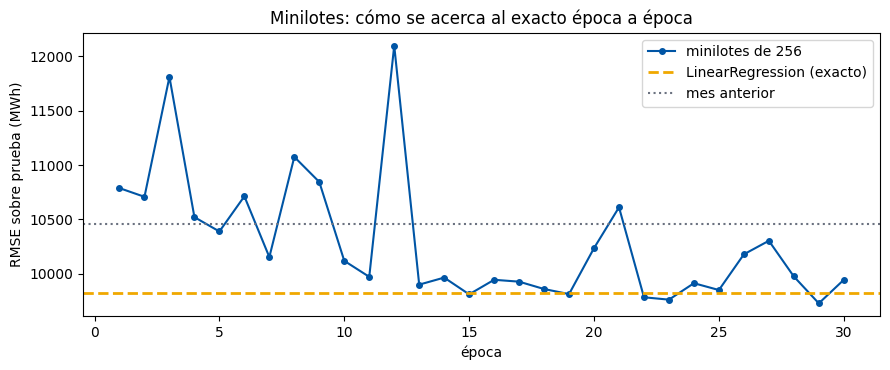

In [26]:
sgd_mini = SGDRegressor(eta0=0.0001, learning_rate="constant", random_state=2026)
rng = np.random.default_rng(2026)
LOTE, EPOCAS = 256, 30
curva = []; t0 = time.perf_counter()
for epoca in range(EPOCAS):
    orden = rng.permutation(len(X_ent_esc))
    for i in range(0, len(orden), LOTE):
        idx = orden[i:i + LOTE]
        sgd_mini.partial_fit(X_ent_esc[idx], y_np[idx])
    curva.append(rmse(y_pru, sgd_mini.predict(X_pru_esc)))
t_mini = (time.perf_counter() - t0) * 1000
pred_mini = sgd_mini.predict(X_pru_esc)
resultados[f"SGD minilotes de {LOTE}, {EPOCAS} épocas"] = {"RMSE": rmse(y_pru, pred_mini), "MAE": mean_absolute_error(y_pru, pred_mini),
                                                        "R²": r2_score(y_pru, pred_mini), "ajuste (ms)": t_mini, "modelo": sgd_mini}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, EPOCAS + 1), curva, marker="o", ms=4, color=AZUL, label=f"minilotes de {LOTE}")
ax.axhline(resultados["LinearRegression"]["RMSE"], color=AMBAR, lw=2, ls="--", label="LinearRegression (exacto)")
ax.axhline(resultados["línea de base (mes anterior)"]["RMSE"], color=GRIS, lw=1.5, ls=":", label="mes anterior")
ax.set_xlabel("época"); ax.set_ylabel("RMSE sobre prueba (MWh)"); ax.legend(); ax.set_title("Minilotes: cómo se acerca al exacto época a época")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">A diferencia del gimnasio, la curva no baja suave: salta. Con tasa constante, cada minilote que trae una distribuidora gigante da un paso enorme y desacomoda los coeficientes; la época siguiente lo corrige. El ruido del estocástico se amplifica cuando el objetivo tiene cola larga. Por eso el resultado final de los minilotes depende de en qué época se corte, y por eso <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">LinearRegression</code> (exacto) sigue siendo la opción natural con estos datos.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">6 · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

In [27]:
matriz = pd.DataFrame({k: {m: v[m] for m in ["RMSE", "MAE", "R²", "ajuste (ms)"]} for k, v in resultados.items()}).T
matriz = matriz.drop(index="SGD sin escalar")        # su error descomunal aplasta la escala de color; ya se vio arriba
(matriz.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.4f}", "ajuste (ms)": "{:.1f}"})
       .background_gradient(subset=["RMSE", "MAE", "ajuste (ms)"], cmap="RdYlGn_r")
       .background_gradient(subset=["R²"], cmap="RdYlGn"))

,RMSE,MAE,R²,ajuste (ms)
línea de base (media),"66,699","17,949",-0.0047,1.5
línea de base (mes anterior),"10,463","1,545",0.9753,0.0
LinearRegression,"9,825","1,605",0.9782,61.0
LinearRegression sin sesgo,"13,759","10,388",0.9572,80.8
"SGD por defecto (eta0=0.01, invscaling)","9,994","1,886",0.9774,145.6
"SGD eta0=0.001, adaptive","9,818","1,606",0.9782,523.9
"SGD eta0=0.0001, max_iter=2 (cortado)","18,940","6,565",0.9190,50.7
"SGD minilotes de 256, 30 épocas","9,946","1,624",0.9777,3052.9


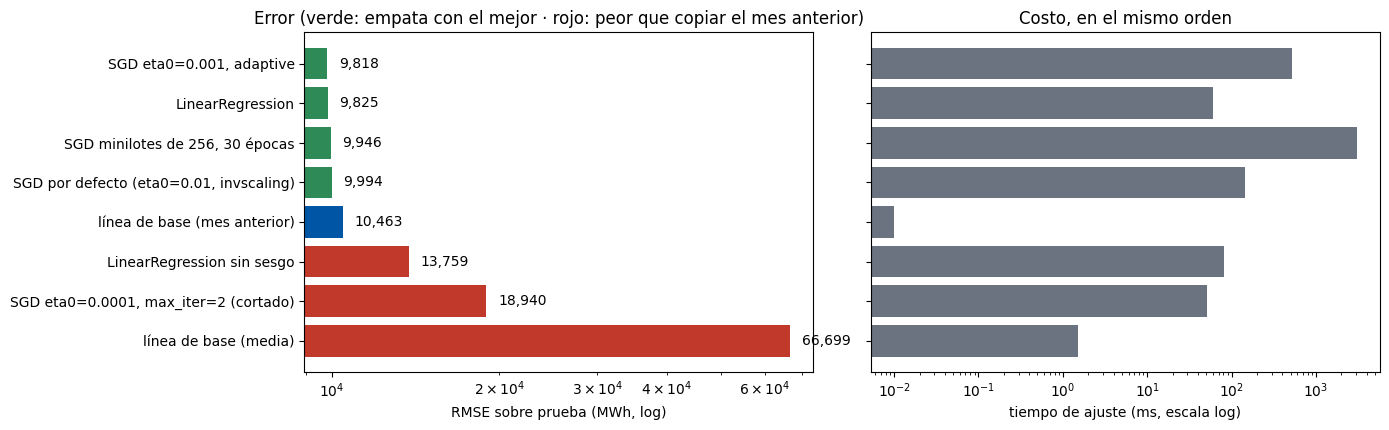

In [28]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
orden = matriz.sort_values("RMSE")
mejor = orden["RMSE"].min()
colores = [VERDE if r <= mejor * 1.02 else (ROJO if r > resultados["línea de base (mes anterior)"]["RMSE"] else AZUL) for r in orden["RMSE"]]
a.barh(orden.index, orden["RMSE"], color=colores); a.invert_yaxis(); a.set_xscale("log"); a.set_xlabel("RMSE sobre prueba (MWh, log)")
a.set_title("Error (verde: empata con el mejor · rojo: peor que copiar el mes anterior)")
for i, v in enumerate(orden["RMSE"]): a.text(v * 1.05, i, f"{v:,.0f}", va="center")
b.barh(orden.index, orden["ajuste (ms)"].clip(lower=0.01), color=GRIS); b.set_xscale("log")
b.set_xlabel("tiempo de ajuste (ms, escala log)"); b.set_title("Costo, en el mismo orden")
plt.tight_layout(); plt.show()

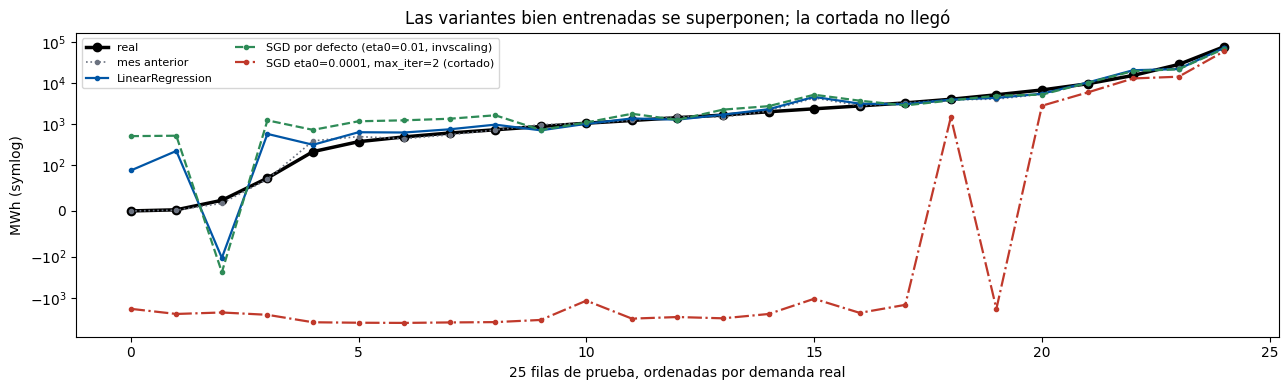

In [29]:
# Las variantes, fila por fila, sobre 25 filas de prueba ordenadas por demanda real
muestra = np.argsort(y_pru.to_numpy())[::len(y_pru) // 25][:25]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y_pru.to_numpy()[muestra], color="black", lw=2.5, marker="o", label="real")
ax.plot(X_pru["lag1"].to_numpy()[muestra], color=GRIS, lw=1.2, ls=":", marker=".", label="mes anterior")
for nombre, color, ls in [("LinearRegression", AZUL, "-"), ("SGD por defecto (eta0=0.01, invscaling)", VERDE, "--"), ("SGD eta0=0.0001, max_iter=2 (cortado)", ROJO, "-.")]:
    ax.plot(resultados[nombre]["modelo"].predict(X_pru.iloc[muestra]), color=color, lw=1.6, ls=ls, marker=".", label=nombre)
ax.set_yscale("symlog", linthresh=100)
ax.set_xlabel("25 filas de prueba, ordenadas por demanda real"); ax.set_ylabel("MWh (symlog)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Las variantes bien entrenadas se superponen; la cortada no llegó")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se elige</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Primero el error</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre prueba y contra las dos líneas de base. Todas las variantes bien entrenadas son la misma recta y empatan. La pregunta de fondo es cuánto le ganan a copiar el mes anterior: si la diferencia es chica, el modelo agrega poco sobre la regla más simple.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Después la estabilidad</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">cross_val_score</code> y pliegues temporales. Si la diferencia entre la recta y la persistencia es menor que la dispersión entre pliegues, no se puede afirmar que la recta sea mejor.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Después el costo</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Con ~30 000 filas la ecuación normal sigue siendo instantánea: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">LinearRegression</code> gana. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">partial_fit</code> tendría sentido si se quisiera actualizar el modelo mes a mes con los datos nuevos del portal.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que no se elige</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las variantes que no llegaron no son peores modelos: son la misma recta mal entrenada. Y los coeficientes individuales de los rezagos no se interpretan uno por uno, por la multicolinealidad.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">7 · Usarlo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El flujo se usa con una tabla con las mismas seis columnas, y la predicción sale en MWh. Ejemplo: dos agentes hipotéticos para enero de 2020.</p></div>

In [30]:
nuevo = pd.DataFrame([
    {"lag1": 52000, "lag2": 48000, "lag12": 55000, "mes_num": 1, "es_gran_usuario": 0, "es_residencial": 1},   # una distribuidora mediana, residencial
    {"lag1": 3100,  "lag2": 3000,  "lag12": np.nan, "mes_num": 1, "es_gran_usuario": 1, "es_residencial": 0},  # un gran usuario sin historia de hace un año
])
nuevo["demanda_MWh (predicción)"] = modelo.predict(nuevo[PREDICTORAS]).round(0)
nuevo

,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial,demanda_MWh (predicción)
0,52000,48000,55000.0,1,0,1,54022.0
1,3100,3000,NaN,1,1,0,2708.0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas, con su predicción explicada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas de prueba a lo largo de todo el rango, con lo real, lo predicho, el error y el aporte de cada columna (coeficiente × valor escalado).</p></div>

In [31]:
orden_real = np.argsort(y_pru.to_numpy())
elegidos = orden_real[np.linspace(0.05 * len(orden_real), len(orden_real) - 1, 10).astype(int)]   # desde el percentil 5: abajo hay demandas ≈ 0 donde el % no tiene sentido
Z = X_pru_esc[elegidos]
aportes = pd.DataFrame(recta.coef_ * Z, columns=PREDICTORAS, index=X_pru.index[elegidos])
explicado = X_pru.iloc[elegidos].copy()
explicado.insert(0, "serie", datos.loc[X_pru.index[elegidos], "serie"].str.slice(0, 40))
explicado["real"] = y_pru.iloc[elegidos].round(0)
explicado["predicho"] = (recta.intercept_ + aportes.sum(axis=1)).round(0)
explicado["error"] = (explicado["real"] - explicado["predicho"]).round(0)
explicado["error %"] = (100 * explicado["error"] / explicado["real"].abs().clip(lower=1)).round(1)
explicado.index.name = "fila"
(explicado.style.format(precision=0, thousands=".").format("{:+.1f}", subset=["error %"])
    .background_gradient(subset=["error %"], cmap="RdYlGn_r", gmap=explicado["error %"].abs(), vmin=0, vmax=50)
    .set_caption("Datos, real y predicho; el error relativo en color: verde cerca de 0 %, rojo a 50 % o más"))

,serie,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial,real,predicho,error,error %
fila,,,,,,,,,,,
36839,CRAWSOUW | TARIFA BASE ELECTRODEPENDIENT,5,5,3,1,0,1,5,-120,125,+2500.0
35128,C3AR3A3W | TARIFA USUARIO NO RESIDENCIAL,208,205,140,11,0,0,189,319,-130,-68.8
32754,AKZOGAOY | GUMAS/AUTOGENERADORES,550,519,585,8,1,0,549,627,-78,-14.2
34320,ARCOSLDY | GUMAS/AUTOGENERADORES,817,892,1.258,10,1,0,911,1.050,-139,-15.3
34051,MAZZP21Y | GUMAS/AUTOGENERADORES,1.481,1.417,1.314,9,1,0,1.412,1.627,-215,-15.2
34915,RAYER2MY | GUMAS/AUTOGENERADORES,2.489,2.971,2.623,10,1,0,2.167,2.718,-551,-25.4
35118,BUNGCA1Z | GUMAS/AUTOGENERADORES,2.996,3.283,2.631,11,1,0,3.340,3.263,77,+2.3
36266,FATESFOY | GUMAS/AUTOGENERADORES,7.482,7.581,7.490,12,1,0,6.279,7.993,-1.714,-27.3
36697,CCOMODUW | RESIDENCIAL,19.123,19.767,18.742,1,0,1,19.738,19.510,228,+1.2


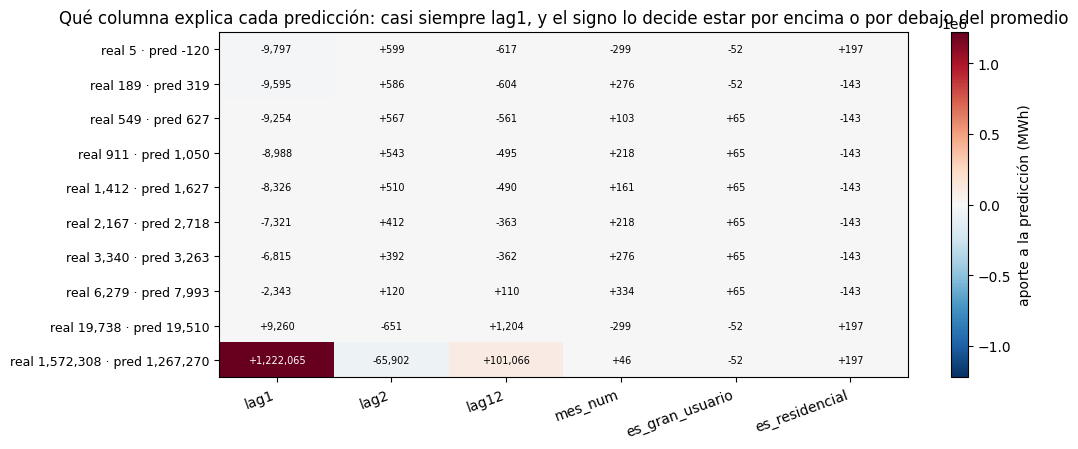

In [32]:
lim_ap = np.abs(aportes.to_numpy()).max()
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(aportes.to_numpy(), cmap="RdBu_r", vmin=-lim_ap, vmax=lim_ap, aspect="auto")
ax.set_xticks(range(len(PREDICTORAS))); ax.set_xticklabels(PREDICTORAS, rotation=20, ha="right")
ax.set_yticks(range(len(elegidos))); ax.set_yticklabels([f"real {r:,.0f} · pred {p:,.0f}" for r, p in zip(explicado["real"], explicado["predicho"])], fontsize=9)
for i in range(aportes.shape[0]):
    for j in range(aportes.shape[1]):
        v = aportes.iloc[i, j]; ax.text(j, i, f"{v:+,.0f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > lim_ap / 2 else "black")
plt.colorbar(im, ax=ax, label="aporte a la predicción (MWh)")
ax.set_title("Qué columna explica cada predicción: casi siempre lag1, y el signo lo decide estar por encima o por debajo del promedio")
plt.tight_layout(); plt.show()

In [33]:
medias = pd.Series(preparar[-1].mean_, index=PREDICTORAS)
def num(v): return f"{v:,.0f}".replace(",", ".")
escalado = pd.DataFrame(Z, columns=PREDICTORAS, index=aportes.index)
for fila_id in aportes.index:
    fila = explicado.loc[fila_id]; ap = aportes.loc[fila_id]
    top = ap.abs().sort_values(ascending=False).index[:2]
    partes = []
    for col in top:
        valor = X_pru.loc[fila_id, col]
        valor_txt = "faltante, imputado" if pd.isna(valor) else num(valor)
        lado = "por encima" if escalado.loc[fila_id, col] > 0 else "por debajo"
        partes.append(f"{num(ap[col])} por {col} ({valor_txt}, {lado} del promedio de {num(medias[col])})")
    veredicto = "acierto" if abs(fila["error %"]) < 10 else ("se queda corto" if fila["error"] > 0 else "se pasa")
    print(f"{fila['serie']}: predicho {num(fila['predicho'])}, real {num(fila['real'])} MWh ({veredicto}, {fila['error %']:+.1f} %). "
          f"Parte de {num(recta.intercept_)}; " + "; ".join(partes) + ".")

CRAWSOUW | TARIFA BASE ELECTRODEPENDIENT: predicho -120, real 5 MWh (se queda corto, +2500.0 %). Parte de 9.851; -9.797 por lag1 (5, por debajo del promedio de 9.833); -617 por lag12 (3, por debajo del promedio de 6.355).
C3AR3A3W | TARIFA USUARIO NO RESIDENCIAL: predicho 319, real 189 MWh (se pasa, -68.8 %). Parte de 9.851; -9.595 por lag1 (208, por debajo del promedio de 9.833); -604 por lag12 (140, por debajo del promedio de 6.355).
AKZOGAOY | GUMAS/AUTOGENERADORES: predicho 627, real 549 MWh (se pasa, -14.2 %). Parte de 9.851; -9.254 por lag1 (550, por debajo del promedio de 9.833); 567 por lag2 (519, por debajo del promedio de 9.479).
ARCOSLDY | GUMAS/AUTOGENERADORES: predicho 1.050, real 911 MWh (se pasa, -15.3 %). Parte de 9.851; -8.988 por lag1 (817, por debajo del promedio de 9.833); 543 por lag2 (892, por debajo del promedio de 9.479).
MAZZP21Y | GUMAS/AUTOGENERADORES: predicho 1.627, real 1.412 MWh (se pasa, -15.2 %). Parte de 9.851; -8.326 por lag1 (1.481, por debajo del pr

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Para los agentes chicos, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> está por debajo del promedio y empuja la predicción hacia abajo desde el sesgo; para los grandes, al revés. Los errores relativos más grandes suelen estar en los agentes más chicos, donde unos pocos MWh de diferencia son un porcentaje alto, y la recta puede incluso dar valores negativos: no tiene piso, igual que con las sesiones del gimnasio.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guarda el flujo completo con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code> y una app <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Streamlit</code> lo carga: controles para el mes anterior, dos meses antes, el año anterior, el mes y el tipo de agente.</p></div>

In [34]:
import joblib

joblib.dump(modelo, "modelo_demanda_cammesa.joblib")
cargado = joblib.load("modelo_demanda_cammesa.joblib")
print("Modelo guardado: modelo_demanda_cammesa.joblib")
print("Misma predicción tras guardar y cargar:", np.allclose(cargado.predict(X_pru), modelo.predict(X_pru)))

Modelo guardado: modelo_demanda_cammesa.joblib
Misma predicción tras guardar y cargar: True


In [35]:
%%writefile app_demanda_cammesa.py
# Regresión lineal sobre la demanda CAMMESA · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_demanda_cammesa.py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="Demanda mensual de un agente", layout="centered")
st.title("¿Cuántos MWh va a demandar este agente el mes que viene?")
st.caption("Regresión lineal sobre demanda-ltimos-aos.csv (CAMMESA), con rezagos de 1, 2 y 12 meses.")

@st.cache_resource
def cargar_modelo():
    return joblib.load("modelo_demanda_cammesa.joblib")

modelo = cargar_modelo()

st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 0.0, 1_600_000.0, 50_000.0, step=1000.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 48_000.0, step=1000.0)
tiene_lag12 = c1.checkbox("Conozco la demanda de hace un año", value=True)
lag12 = c1.number_input("Demanda del mismo mes del año pasado (MWh)", 0.0, 1_600_000.0, 52_000.0, step=1000.0, disabled=not tiene_lag12)
mes = c2.slider("Mes a predecir", 1, 12, 1)
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])

fila = pd.DataFrame([{"lag1": lag1, "lag2": lag2, "lag12": lag12 if tiene_lag12 else np.nan, "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])
estimacion = float(modelo.predict(fila)[0])

st.subheader("Predicción")
c3, c4 = st.columns(2)
c3.metric("Demanda estimada", f"{estimacion:,.0f} MWh", delta=f"{estimacion - lag1:+,.0f} vs. mes anterior")
c4.metric("Copiar el mes anterior daría", f"{lag1:,.0f} MWh")
if estimacion < 0:
    st.warning("La recta predice una demanda negativa: no tiene piso. Es uno de sus límites.")

curva = pd.concat([fila] * 200, ignore_index=True)
curva["lag1"] = np.linspace(0, max(lag1 * 2, 1000), 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva["lag1"], modelo.predict(curva), color="#c0392b", lw=2, label="predicción según la recta")
ax.plot(curva["lag1"], curva["lag1"], color="gray", ls=":", label="copiar el mes anterior")
ax.scatter([lag1], [estimacion], s=200, marker="*", color="#c0392b", zorder=5, label="este agente")
ax.set_xlabel("demanda del mes anterior (MWh)"); ax.set_ylabel("demanda predicha (MWh)"); ax.legend()
ax.set_title("Moviendo solo el mes anterior: la recta casi copia, con una corrección")
st.pyplot(fig)

with st.expander("Ver la fila que recibe el modelo"):
    st.dataframe(fila)

Writing app_demanda_cammesa.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Hace falta <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">pip install streamlit</code> en el entorno del cuaderno (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">conda activate aa2026</code> primero).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Forma recomendada:</b> en una terminal, desde la carpeta del cuaderno, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_demanda_cammesa.py</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza en modo sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [37]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_demanda_cammesa.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">8 · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El algoritmo es exactamente el de la clase: imputar, escalar, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">LinearRegression</code>, y las mismas variantes llegan a la misma recta. Lo que cambió fue todo lo de alrededor, porque el dataset es otro tipo de problema.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Las predictoras hubo que construirlas.</b> Con columnas casi todas categóricas, la señal está en la historia de cada serie: los rezagos. Sin ellos la recta no le gana a la media.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El corte es temporal y hay dos líneas de base.</b> El R² altísimo se lo da casi todo el mes anterior; la mejora real de la recta se mide contra copiar el mes pasado, y es modesta.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>La multicolinealidad cambia la lectura.</b> Las predicciones son buenas, pero los coeficientes de cada rezago por separado no son estables ni interpretables; la suma sí. Y el gradiente camina lento por un valle angosto.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Mejoras que quedan planteadas:</b> modelar el logaritmo de la demanda (el error de los gigantes domina el RMSE); codificar el mes con indicadores o seno/coseno; imputar <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> con algo mejor que la mediana; y Ridge para estabilizar los coeficientes.</p></div>